# VIC: Introduction to Visual Computing - 2026
## Assignment 1

Due date: 6/2/26

This assignment has three problems that you need to solve.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## 1. Bilateral Filter

For the first problem, you need to implement a bilateral filter for image smoothing,

$$BF[I]_p = \frac{1}{W_p}\sum_{q \in N(p)}G_{\sigma_S}(p - q) \times G_{\sigma_R}(I_p - I_q) \times I_q$$

$${W_p} = \sum_{q \in N(p)}G_{\sigma_S}(p - q) \times G_{\sigma_R}(I_p - I_q)$$

for each pixel *coordinate* $p$ of image $I$, where $N(p)$ is the neighbourhood of $p$, $G_{\sigma_S}$ is a 2D Gaussian with zero mean and covariance matrix $diag([\sigma_S^2, \sigma_S^2])$ and $G_{\sigma_R}$ is a 1D Gaussian with std $\sigma_R$. Typically, $\sigma_R = \sqrt(Var(I))$. Test the filtering and observe the effect of the hyperparameters. Evaluate the performance with the Gaussian smoothing visually and write a small comment with some conclusions.

**N.B** As a non-linear filter, the algorithm is allowed to take several seconds to run. You are encouraged to think of ways to improve the runtime.

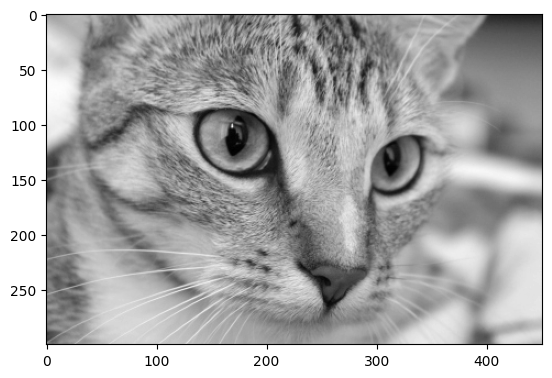

In [ ]:
from skimage import data
from skimage.color import rgb2gray

img = rgb2gray(data.chelsea())

plt.imshow(img, cmap="gray")

We define a helper function for generating a Guassian kernel. The parameter `sigma` controls the variance, and `neigh` indicates the domain of the Gaussian.

In [ ]:
from scipy.signal.windows import gaussian
from scipy.stats import norm


def generate_gaussian_kernel(sigma, neigh):
    """
    Gaussian kernel generator.

    Inputs:
        sigma:     Std of Gaussian
        neigh:     Size of window
    """

    kernel_1d = gaussian(M=neigh, std=sigma)
    kernel = np.outer(kernel_1d, kernel_1d)

    return kernel / np.sum(kernel)

Complete the bilateral filter function below. The filter may be sensitive to the choice of parameters, so you are advised to use the provided parameters as a guide.

In [ ]:
from numpy.lib.stride_tricks import sliding_window_view


def bilateral_filtering(img, sigma_s, sigma_r):
    """
    Bilateral Filtering.

    Inputs:
        img:           The input image
        sigma_s:       Std of the spatial Gaussian
        sigma_r:       Std of the range Gaussian

    Outputs:
        bilateral_img    A smoothed image
    """

    h, w = img.shape
    bilateral_img = np.zeros_like(img)

    neigh = int(sigma_s * 6 + 1)  # ensure approx. 3 std

    pad = (neigh - 1) // 2
    img = np.pad(img, pad_width=pad)

    gaussian_kernel = generate_gaussian_kernel(sigma_s, neigh)

    patches = sliding_window_view(img, (neigh, neigh))
    centers = img[pad : pad + h, pad : pad + w][:, :, None, None]

    range_kernel = np.exp(-((patches - centers) ** 2) / (2 * sigma_r**2))

    weights = gaussian_kernel * range_kernel
    weights /= np.sum(weights, axis=(2, 3), keepdims=True)

    bilateral_img = np.sum(weights * patches, axis=(2, 3))

    # Return the result
    return bilateral_img

<function matplotlib.pyplot.show(close=None, block=None)>

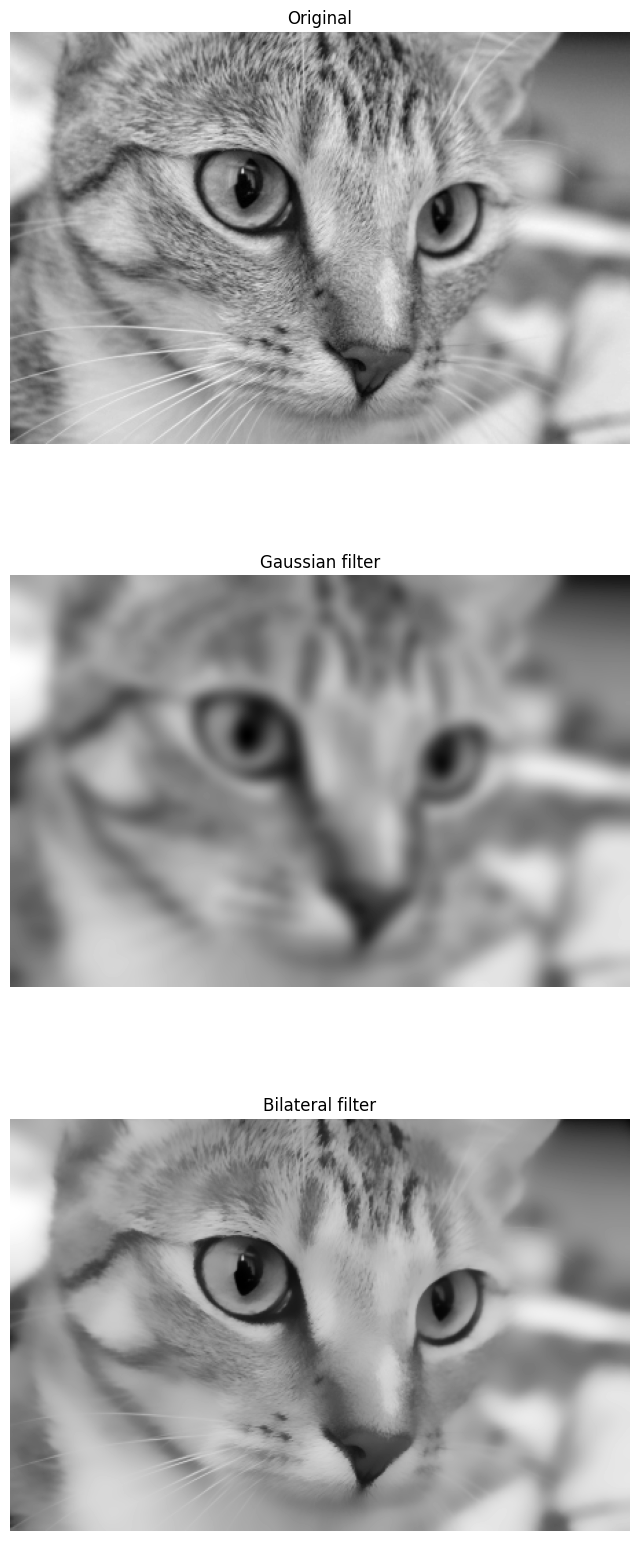

In [ ]:
from scipy.ndimage import gaussian_filter

sigma_s = 5
sigma_r = 0.1

bf_img = bilateral_filtering(img, sigma_s, sigma_r)

g_img = gaussian_filter(img, sigma_s)

fig, axes = plt.subplots(figsize=(8, 20), nrows=3)

for i, (image, name) in enumerate(
    zip([img, g_img, bf_img], ["Original", "Gaussian filter", "Bilateral filter"])
):
    axes[i].imshow(image, cmap="gray")
    axes[i].axis("off")
    axes[i].set_title(name)

plt.show

<font color='green'>
The Gaussian filter produces uniform smoothing across the image, which effectively reduces noise but also blurs edges and fine structures. In contrast, the bilateral filter preserves sharp edges while still smoothing within homogeneous regions, since the range kernel suppresses averaging across large intensity differences. As a result, edges remain well localized in the bilateral output, whereas they are noticeably smoothed in the Gaussian-filtered image.
</font>

## 2. Canny Edge Detector

Now you need to implement your own Canny edge detector. Recall that the Canny edge detector consists of the following steps:

* Smoothing the image using a Gaussian filter
* Computing the gradient of the image&mdash;magnitude and direction&mdash;using the Sobel operator
* Non-maximum suppression using the gradient's magnitude and direction
* Double thresholding
* Edge connectivity using hysterisis

#### 2.A Smoothing

This standard smoothing operation can be implemented using the `scipy.ndimage.gaussian_filter` function.
Alternatively, you can define your own, or use `generate_gaussian_kernel` and `scipy.ndimage.convolve`

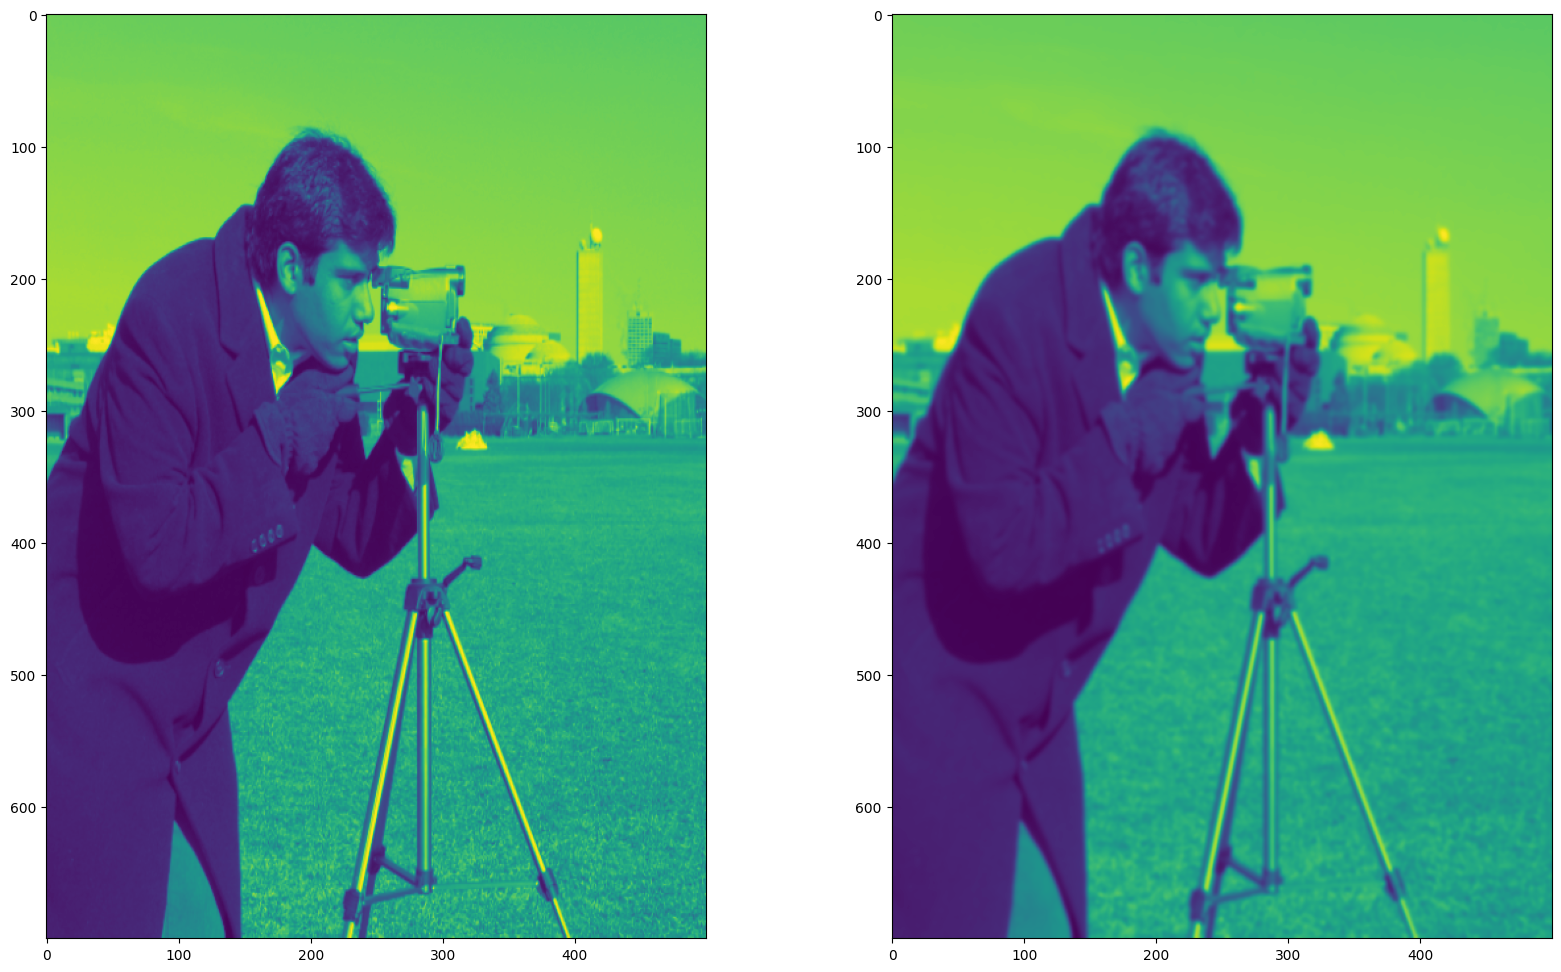

In [ ]:
from scipy.ndimage import gaussian_filter
from scipy.ndimage import convolve
from skimage.transform import resize

img = data.camera() / 255.0
img = resize(img, output_shape=(700, 500))


def gaussian_smoothing(img):
    sigma = 1.4
    smoothed_img = gaussian_filter(img, sigma=sigma)
    return smoothed_img


smoothed = gaussian_smoothing(img)

fig, axes = plt.subplots(figsize=(20, 12), ncols=2)

axes[0].imshow(img)
axes[1].imshow(smoothed)

#### 2.B Gradients

Use the Sobel operators to compute $g_x$ and $g_y$. The magnitude and direction of the gradient can be computed as
$g = \sqrt{g_x^2 + g_y^2}$, and $\theta = atan2(g_x, g_y)$.

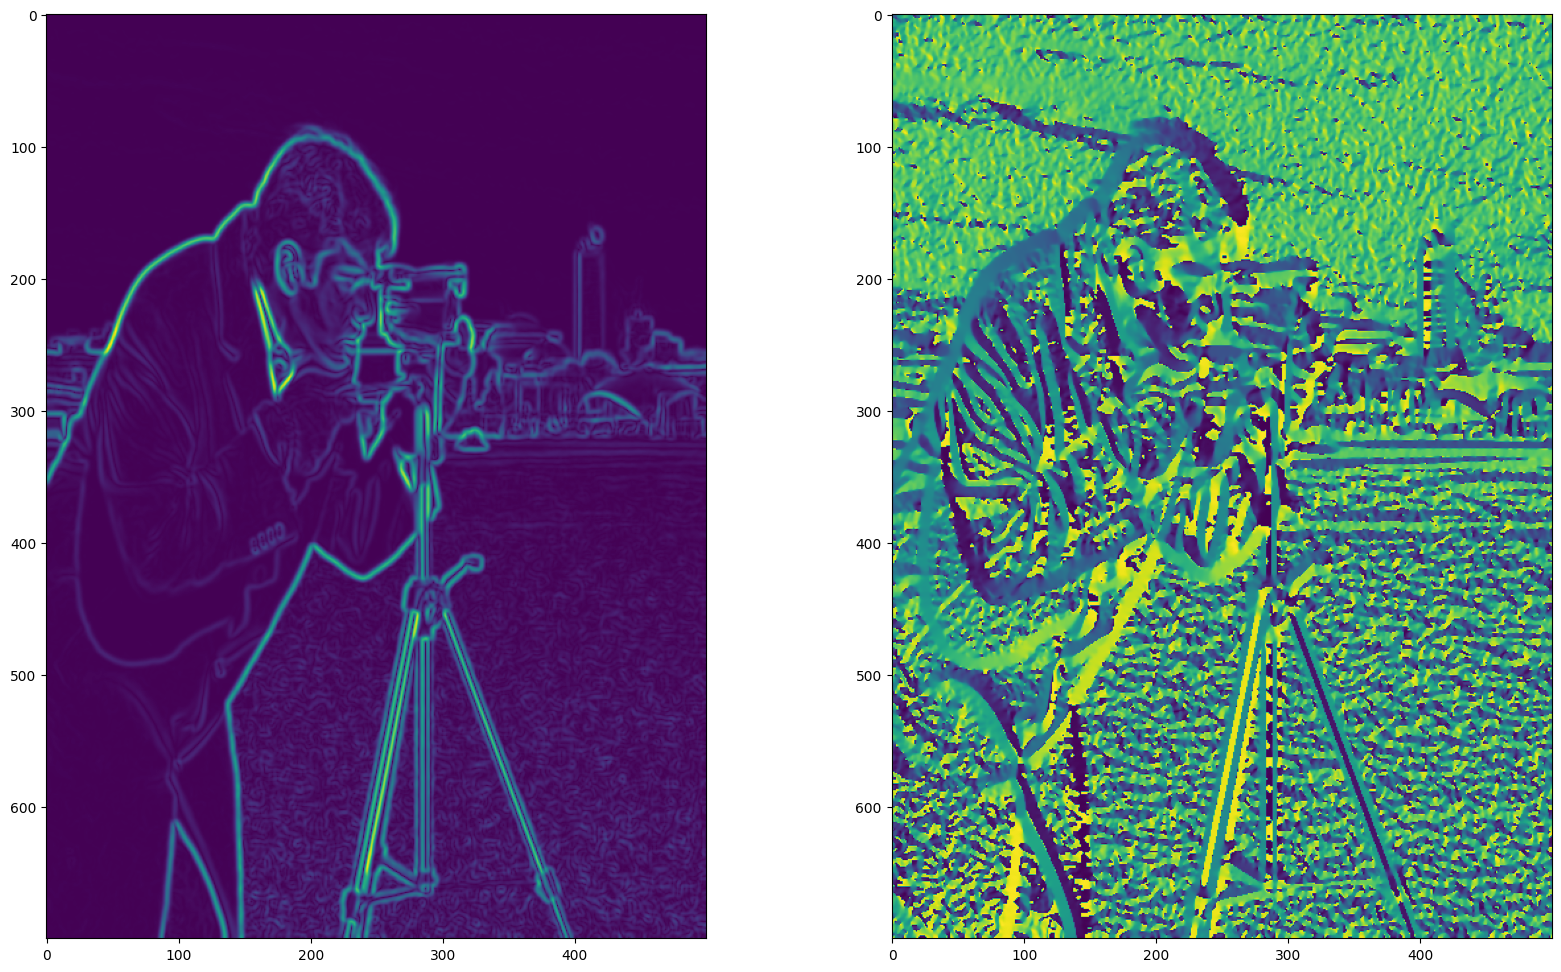

In [ ]:
def gradient(img):
    # Sobel kernels
    Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])

    Ky = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])

    gx = convolve(img, Kx, mode="reflect")
    gy = convolve(img, Ky, mode="reflect")

    # Gradient magnitude and direction
    g_magnitude = np.sqrt(gx**2 + gy**2)
    g_dir = np.arctan2(gy, gx)

    return g_magnitude, g_dir


fig, axes = plt.subplots(figsize=(20, 12), ncols=2)

g_magnitude, g_dir = gradient(smoothed)

axes[0].imshow(g_magnitude)
axes[1].imshow(g_dir)

#### 2.C Non-maximum suppression

We will take a simplistic approach to non-maximum suppression. The idea is to suppress pixels adjacent to the edges, where edges are identified by strong gradients. First, quantise the gradient directions $\theta$ into one of four values: $\hat{\theta} \in \{0, \frac{\pi}{4}$, $\frac{\pi}{2}$, $\frac{3\pi}{4}\}$. If $\theta$ is negative it should first be normalised to $\theta \leftarrow\theta + \pi$. Then, if the gradient magnitude of a given pixel is larger than those of the two adjacent pixels in the $\hat{\theta}$ and $\hat{\theta} - \pi$ directions (i.e. north/south, east/west, northeast/southwest, or northwest/southeast), it is preserved. Otherwise, it is suppressed.

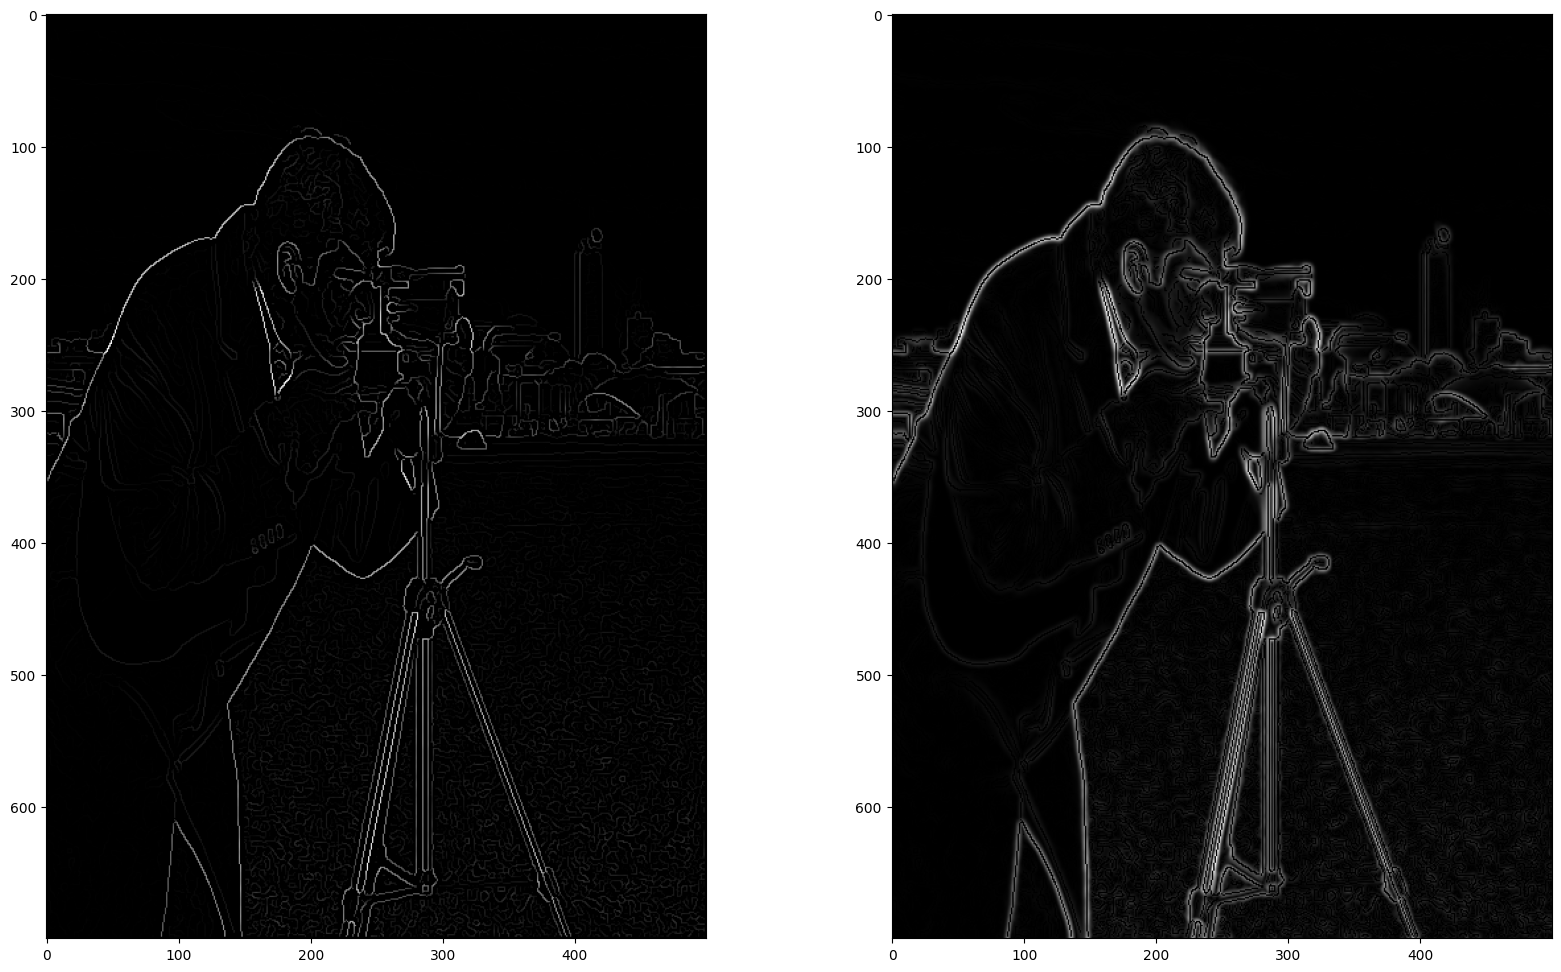

In [ ]:
def non_maximum_suppression(g_magnitude, g_dir):
    h, w = g_magnitude.shape
    g_max = np.zeros_like(g_magnitude)

    theta = g_dir.copy()
    theta[theta < 0] += np.pi

    theta_q = np.zeros_like(theta)

    theta_q[(theta < np.pi / 8) | (theta >= 7 * np.pi / 8)] = 0
    theta_q[(theta >= np.pi / 8) & (theta < 3 * np.pi / 8)] = np.pi / 4
    theta_q[(theta >= 3 * np.pi / 8) & (theta < 5 * np.pi / 8)] = np.pi / 2
    theta_q[(theta >= 5 * np.pi / 8) & (theta < 7 * np.pi / 8)] = 3 * np.pi / 4

    for i in range(1, h - 1):
        for j in range(1, w - 1):
            if theta_q[i, j] == 0:
                n1 = g_magnitude[i, j + 1]
                n2 = g_magnitude[i, j - 1]

            elif theta_q[i, j] == np.pi / 4:
                n1 = g_magnitude[i - 1, j + 1]
                n2 = g_magnitude[i + 1, j - 1]

            elif theta_q[i, j] == np.pi / 2:
                n1 = g_magnitude[i - 1, j]
                n2 = g_magnitude[i + 1, j]

            else:
                n1 = g_magnitude[i - 1, j - 1]
                n2 = g_magnitude[i + 1, j + 1]

            if g_magnitude[i, j] >= n1 and g_magnitude[i, j] >= n2:
                g_max[i, j] = g_magnitude[i, j]

    return g_max


fig, axes = plt.subplots(figsize=(20, 12), ncols=2)

g_max = non_maximum_suppression(g_magnitude, g_dir)

axes[0].imshow(g_max, cmap="gray")
axes[1].imshow(g_magnitude - g_max, cmap="gray")

#### 2.D Double thresholding

Double thresholding can be implemented by fixing two thresholds, `lo` and `hi`. Accordingly, you will have two *levels* of gradient magnitudes&mdash;*weak* and *strong*. Pixels where the magnitude of the gradient is greater than `hi` will be designated *strong* points, while those where it lies between `lo` and `high` will be designated *weak*.

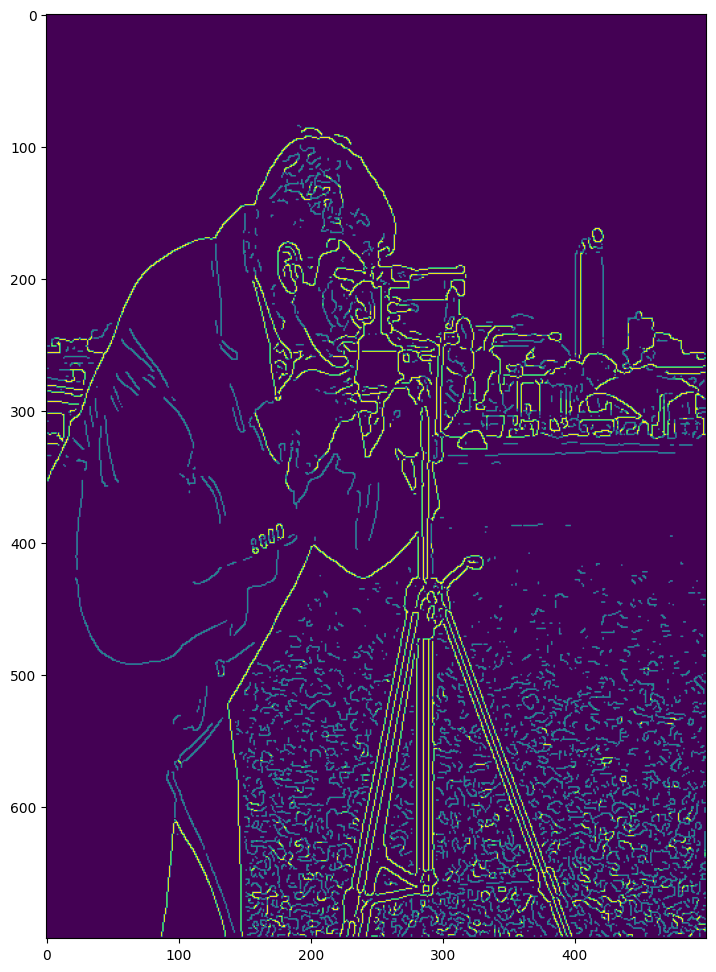

In [ ]:
def double_thresholding(g_max, thresh_lo, thresh_hi):
    thresh_img = np.zeros_like(g_max, dtype=np.uint8)

    strong = g_max >= thresh_hi
    weak = (g_max >= thresh_lo) & (g_max < thresh_hi)

    thresh_img[strong] = 2
    thresh_img[weak] = 1

    return thresh_img


thresh_img = double_thresholding(g_max, thresh_lo=0.1, thresh_hi=0.2)

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(thresh_img)

#### 2.E Edge connectivity

Finally, we decide on edge connectivity as follows:
* All pixels with strong gradients belong to edges, termed *definite edges*.
* All pixels with weak gradients belong to edges only if they are connected to definite edges.

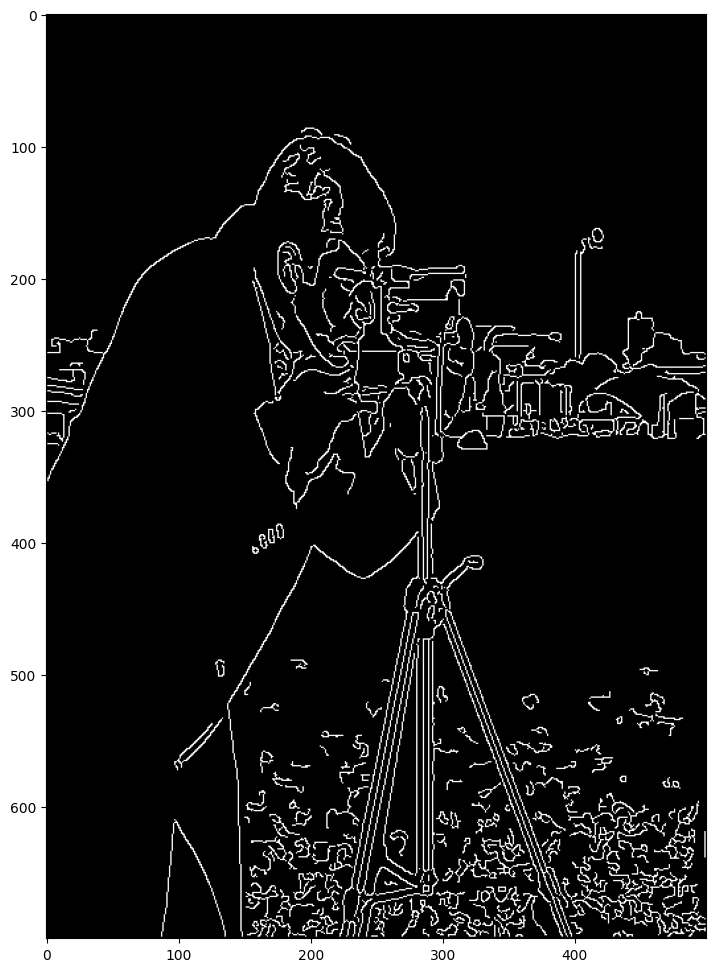

In [ ]:
def connectivity(thresh_img):
    h, w = thresh_img.shape
    edge_img = np.zeros_like(thresh_img, dtype=np.uint8)

    strong = 2
    weak = 1
    edge_img[thresh_img == strong] = 1

    changed = True
    while changed:
        changed = False
        for i in range(1, h - 1):
            for j in range(1, w - 1):
                if thresh_img[i, j] == weak and edge_img[i, j] == 0:
                    if np.any(edge_img[i - 1 : i + 2, j - 1 : j + 2] == 1):
                        edge_img[i, j] = 1
                        changed = True

    return edge_img


edge_img = connectivity(thresh_img)

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(edge_img, cmap="gray")

Once you complete the above functions, you can run the full pipeline below:

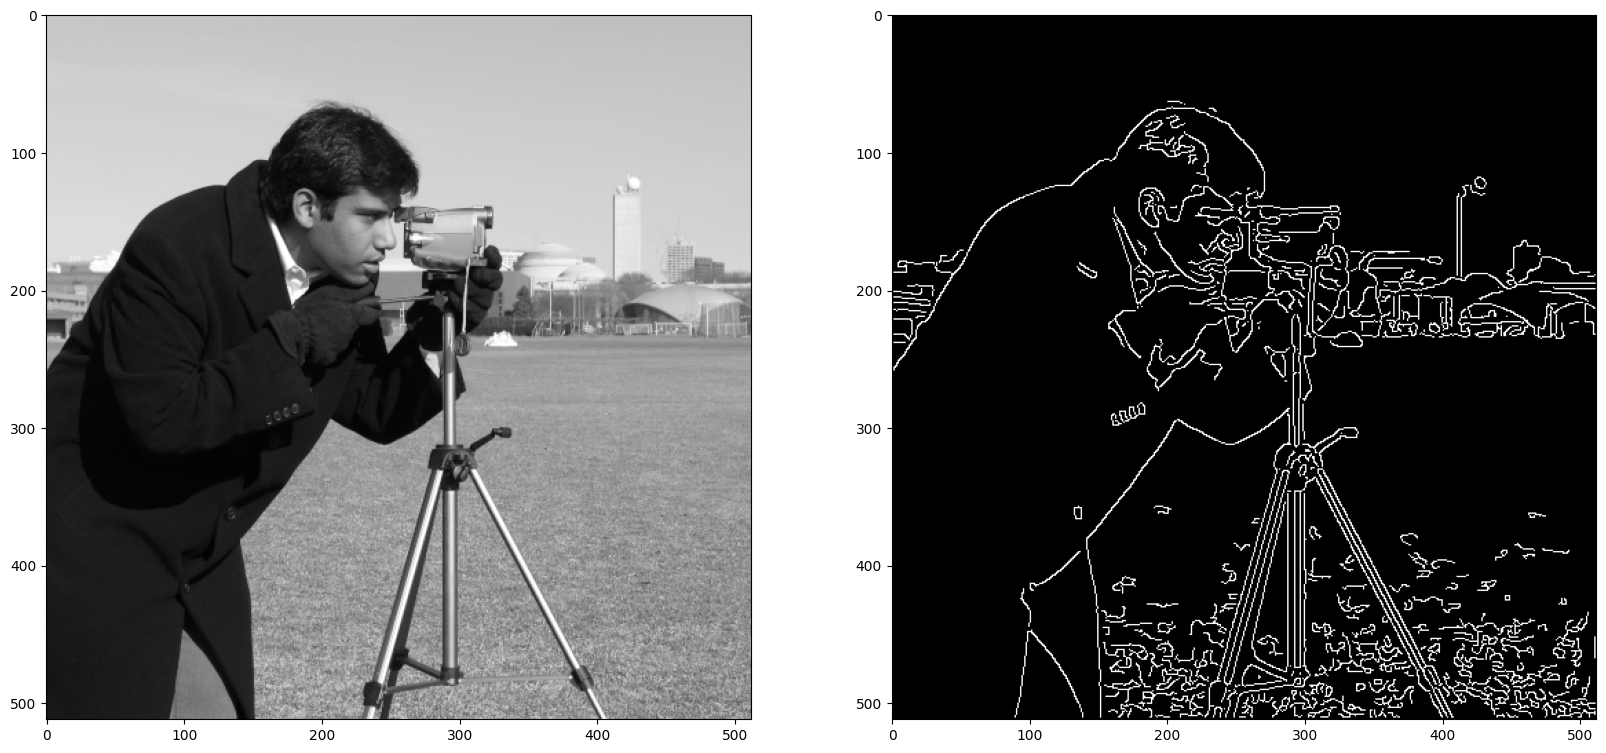

In [19]:
def canny_edge_detector(img, thresh_lo=0.1, thresh_hi=0.2):
    """
    The Canny edge detector.

    Inputs:
        img              The input image
        thresh_lo        The fraction of the maximum gradient magnitude which will
                         be considered the lo threshold.
        thresh_hi        The fraction of the maximum gradient magnitude which will
                         be considered the hi threshold. Ideally should be 2x to 3x
                         thresh_lo.

    Outputs:
        edge_img         A binary image, with pixels lying on edges marked with a 1,
                         and others with a 0.
    """

    # Smooth the image first.
    smoothed = gaussian_smoothing(img)

    # Find gradient magnitude and direction
    g_magnitude, g_dir = gradient(smoothed)

    # Non-maximum suppression
    g_max = non_maximum_suppression(g_magnitude, g_dir)

    # Double thresholding
    thresh_img = double_thresholding(g_max, thresh_lo, thresh_hi)

    # Final edge connectivity
    edge_img = connectivity(thresh_img)

    # Return the result
    return edge_img


img = data.camera() / 255.0

fig, axes = plt.subplots(figsize=(20, 12), ncols=2)

edges = canny_edge_detector(img)

axes[0].imshow(img, cmap="gray")
axes[1].imshow(edges, cmap="gray")

## 3. Scanning an image

For this problem, you are required to "scan" a shopping receipt in several guided steps. The crucial step consists of a Harris corner detector, which you are to **implement from scratch** and tune to the particularities of the problem. Note that **you will be primarily graded on your Harris implementation**, the scanner application is used to provide context.

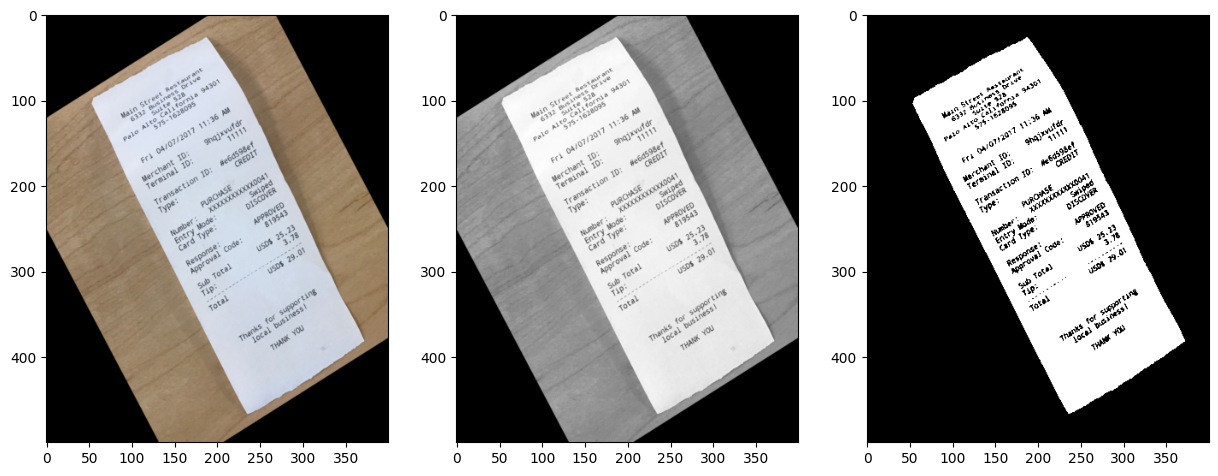

In [20]:
from skimage.io import imread
from skimage.transform import rotate

img_rgb = imread("receipt.png")
img = rgb2gray(img_rgb)

mask = img > 0.7

fig, axes = plt.subplots(figsize=(15, 10), ncols=3)
axes[0].imshow(img_rgb, cmap="gray")
axes[1].imshow(img, cmap="gray")
axes[2].imshow(mask, cmap="gray")

Work on the image mask and apply some morphological filters to remove the text from the receipt. This will make it easier to extract the desired corner features.

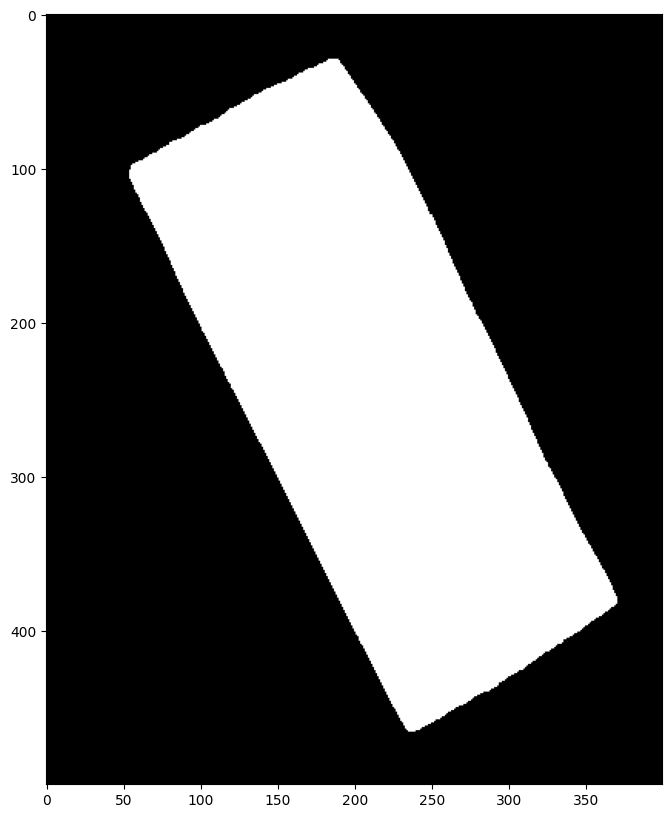

In [ ]:
from skimage.morphology import *

se_text = rectangle(5, 5)
se_fill = rectangle(25, 25)

img_bg = opening(mask, se_text)
img_bg = closing(img_bg, se_fill)

fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(img_bg, cmap="gray")

Implement the Harris corner detector *from scratch*. Tune your parameters to extract **the four corner points only**. You should use `skimage.feature.corner_peaks` to extract your corner coordinates. You can tune the function parameters to whatever values necessary to obtain the four corners of the receipt. The corners should be of the format `np.array([[y1, x1], [y2, x2], ..., [yn, xn]])`. Use `pyplot` to verify.

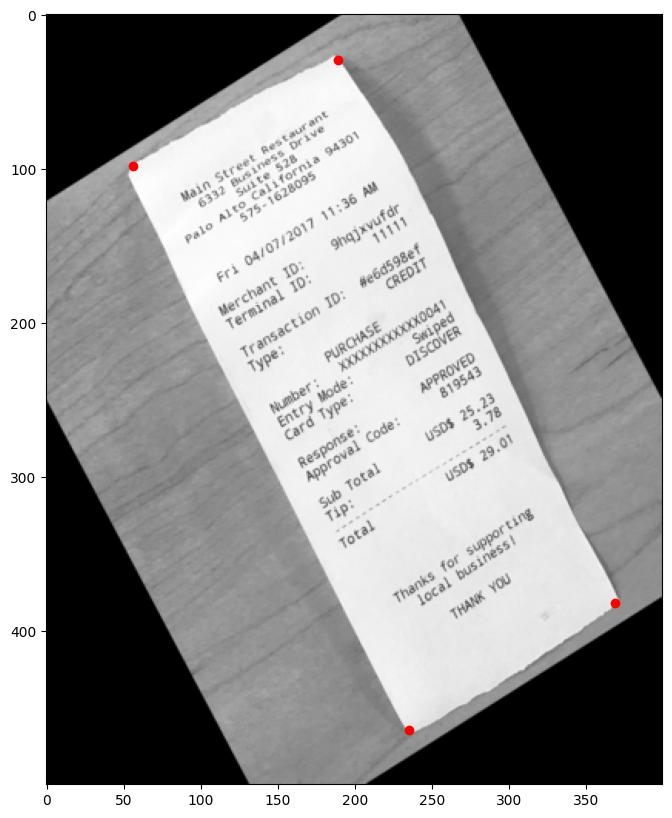

In [ ]:
from skimage.feature import corner_peaks
from scipy import ndimage


def harris_corner_detector(img):
    img = img.astype(float)
    img = ndimage.gaussian_filter(
        img.astype(float), sigma=1
    )  # the last corner was challenging to get right : blurring helped

    Ix = ndimage.sobel(img, axis=1, mode="reflect")
    Iy = ndimage.sobel(img, axis=0, mode="reflect")

    Ixx = ndimage.gaussian_filter(Ix * Ix, sigma=1.5)
    Iyy = ndimage.gaussian_filter(Iy * Iy, sigma=1.5)
    Ixy = ndimage.gaussian_filter(Ix * Iy, sigma=1.5)

    k = 0.04
    det = Ixx * Iyy - Ixy**2
    trace = Ixx + Iyy
    R = det - k * trace**2

    corners = corner_peaks(R, min_distance=25, threshold_rel=0.003, num_peaks=4)

    return corners


corners = harris_corner_detector(img_bg)

fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(img, cmap="gray")
ax.scatter(corners[:, 1], corners[:, 0], color="red")

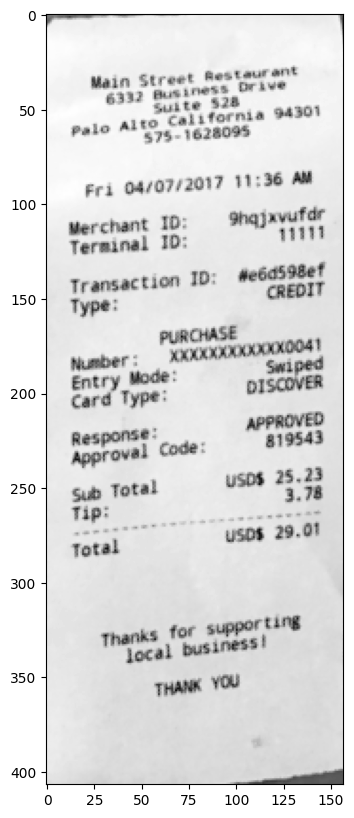

In [50]:
from skimage.transform import estimate_transform, warp


def point_transform(img, corners):
    """
    Point transform.

    Inputs:
        img              The input image
        corners          The corners to rectify

    Outputs:
        warped           The transformed image, aligning the input corners
                         to the rectified targets.
    """

    # (y, x) -> (x, y)
    corners = np.roll(corners, shift=1, axis=1)

    # sort points (required for transform)
    cs = corners[corners[:, 1].argsort()]
    t = cs[:2]
    tl, tr = t[t[:, 0].argsort()]

    b = cs[2:]
    bl, br = b[b[:, 0].argsort()]

    sorted_corners = np.stack([tl, tr, bl, br])

    # calculate dimensions
    width_1 = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    width_2 = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    width = int(max(width_1, width_2))

    height_1 = np.sqrt(((tr[0] - br[0]) ** 2) + ((tr[1] - br[1]) ** 2))
    height_2 = np.sqrt(((tl[0] - bl[0]) ** 2) + ((tl[1] - bl[1]) ** 2))
    height = int(max(height_1, height_2))

    rectified = np.array([[0, 0], [width - 1, 0], [0, height - 1], [width - 1, height - 1]])

    # compute transformation matrix and warp
    M = estimate_transform("euclidean", sorted_corners, rectified)
    warped = warp(img, M.inverse)[:height, :width]

    return warped


warped = point_transform(img, corners)

fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(warped, cmap="gray")

The next step has been written for you. It sorts the corner points, and uses them to compute the geometric transformation to a rectified set of points. **N.B** the requires exactly four corner points.

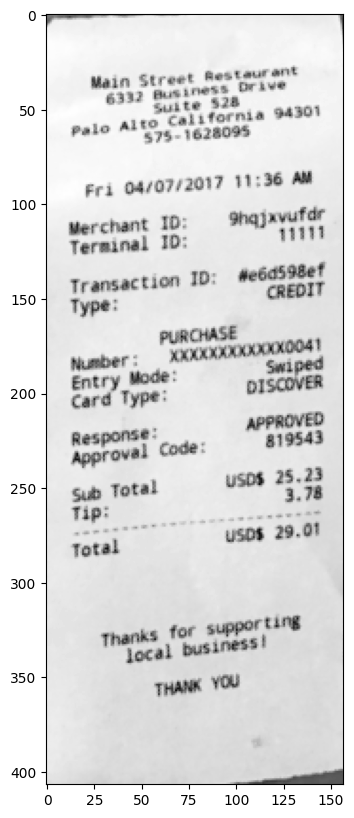

In [51]:
from skimage.transform import estimate_transform, warp


def point_transform(img, corners):
    """
    Point transform.

    Inputs:
        img              The input image
        corners          The corners to rectify

    Outputs:
        warped           The transformed image, aligning the input corners
                         to the rectified targets.
    """

    # (y, x) -> (x, y)
    corners = np.roll(corners, shift=1, axis=1)

    # sort points (required for transform)
    cs = corners[corners[:, 1].argsort()]
    t = cs[:2]
    tl, tr = t[t[:, 0].argsort()]

    b = cs[2:]
    bl, br = b[b[:, 0].argsort()]

    sorted_corners = np.stack([tl, tr, bl, br])

    # calculate dimensions
    width_1 = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    width_2 = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    width = int(max(width_1, width_2))

    height_1 = np.sqrt(((tr[0] - br[0]) ** 2) + ((tr[1] - br[1]) ** 2))
    height_2 = np.sqrt(((tl[0] - bl[0]) ** 2) + ((tl[1] - bl[1]) ** 2))
    height = int(max(height_1, height_2))

    rectified = np.array([[0, 0], [width - 1, 0], [0, height - 1], [width - 1, height - 1]])

    # compute transformation matrix and warp
    M = estimate_transform("euclidean", sorted_corners, rectified)
    warped = warp(img, M.inverse)[:height, :width]

    return warped


warped = point_transform(img, corners)

fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(warped, cmap="gray")

Finally, apply a local threshold with `skimage.filters.threshold_local` to remove the shadow and give it that scanned look:

In [79]:
warped.shape

(407, 157)

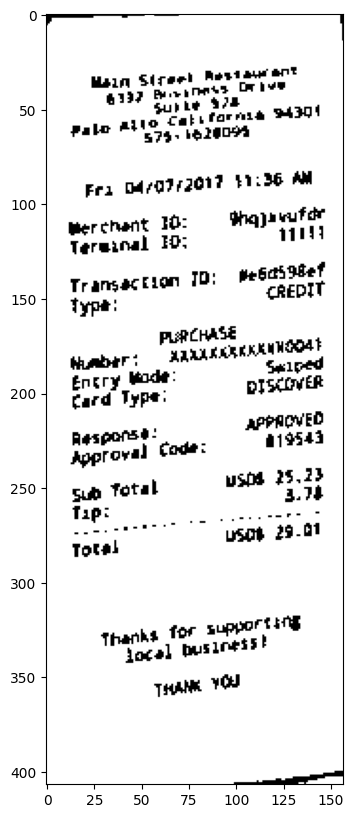

In [112]:
from skimage.filters import threshold_local

block_size = 27
offset = 0.08

thresh = threshold_local(warped, block_size=block_size, offset=offset)
scanned = warped > thresh


fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(scanned, cmap="gray")